# Laser Beam Focusing Calculator

**One laser, one question at a time.** Fill in **Section 2**, then run the section that answers your question.

- Section 3 - focused spot size & Rayleigh range
- Section 4 - beam size at a given position (Δz or WD)
- Section 5 - where to place the sample for a target beam size
- Section 6 - caustic plot
- Section 7 - reference table (2-200 % growth)

Diameters are reported in both μm and mm.

Refs: Siegman *Lasers* (1986); Saleh & Teich (2019); Kogelnik & Li (1966); Goodman (2005); Smith (2007); Shealy & Hoffnagle (2006).

## Section 1 - Setup (run once)

In [81]:
import numpy as np
import matplotlib.pyplot as plt
print('Setup complete. Edit Section 2 next.')

Setup complete. Edit Section 2 next.


## Section 2 - Enter Your Laser

**Gaussian beams:** leave `known_focus_diameter_um = None`. The focal spot is computed from wavelength, M2, f, and the beam diameter at the lens.

**Flat-top / ring beams (imaged spot):** set `known_focus_diameter_um` to the SMALLEST focal-plane spot your laser delivers (from the data sheet). The script then uses that value directly instead of the diffraction limit. Larger spots are reached by defocusing.

Sign convention: Δz > 0 = workpiece moved further from lens, so `WD + Δz` = below focus, `WD - Δz` = above focus.

In [82]:
# ---------- LASER SOURCE ----------
wavelength_nm            = 1070      # nm
beam_diameter_at_lens_mm = 5     # 1/e^2 (Gaussian) or physical (flat-top) diameter at the lens, mm
M2                       = 1.1    # beam quality factor (1.0 = ideal Gaussian)

# ---------- FOCUSING LENS ----------
focal_length_mm     = 163.0          # f - used in equations
working_distance_mm = 193.0          # WD - mechanical stand-off to focal plane

# ---------- BEAM PROFILE ----------
beam_profile     = 'gaussian'        # 'gaussian', 'flat_top', or 'ring'
ring_inner_ratio = 0.0               # ring only: inner/outer diameter ratio

# ---------- KNOWN FOCAL SPOT (flat-top / ring imaged beams) ----------
# Set to your smallest delivered spot in microns, e.g. 50.0
# Leave as None for Gaussian beams (spot is computed instead).
known_focus_diameter_um = None

# ---------- OPTIONAL PROCESS PARAMETERS ----------
power_W         = 200             # W
frequency_Hz    = 0.0                # Hz (0 = CW)
scan_speed_mm_s = 100.0            # mm/s (0 = stationary)

print('Laser loaded.')
print(f'  Profile: {beam_profile}')
if known_focus_diameter_um:
    print(f'  Using KNOWN focal spot = {known_focus_diameter_um} um')
else:
    print('  Focal spot will be computed from optics.')

Laser loaded.
  Profile: gaussian
  Focal spot will be computed from optics.


### Helper functions (run once - no need to edit)

In [83]:
def _focused_diameter_mm():
    # If the focal spot is known (imaged flat-top/ring), use it directly.
    if known_focus_diameter_um is not None and known_focus_diameter_um > 0:
        return known_focus_diameter_um * 1e-3
    lam_mm = wavelength_nm * 1e-6
    f, D = focal_length_mm, beam_diameter_at_lens_mm
    if beam_profile == 'gaussian':
        return 4.0 * M2 * lam_mm * f / (np.pi * D)
    if beam_profile == 'flat_top':
        return 2.44 * lam_mm * f / D
    if beam_profile == 'ring':
        eps = np.array([0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9])
        k   = np.array([1.220,1.216,1.206,1.189,1.166,1.136,1.098,1.049,0.986,0.897])
        kk = float(np.interp(ring_inner_ratio, eps, k))
        return 2.0 * kk * lam_mm * f / D
    raise ValueError(beam_profile)

def _rayleigh_range_mm(d0):
    lam_mm = wavelength_nm * 1e-6
    return np.pi * (d0/2)**2 / (M2 * lam_mm)

def _diameter_at_dz(dz, d0, zR):
    return d0 * np.sqrt(1.0 + (dz/zR)**2)

def _dz_for_diameter(d_t, d0, zR):
    if d_t < d0:
        raise ValueError(f'Target {d_t*1e3:.2f} um is smaller than the focal spot '
                         f'{d0*1e3:.2f} um. You cannot defocus below the waist. '
                         f'Lower known_focus_diameter_um or pick a larger target.')
    return zR * np.sqrt((d_t/d0)**2 - 1.0)

def _peak_irr(d_mm):
    d_cm = d_mm/10.0
    f = 8.0 if beam_profile=='gaussian' else 4.0
    return f * power_W / (np.pi * d_cm**2)

print('Helpers ready.')

Helpers ready.


## Section 3 - Focused Spot Size and Rayleigh Range
Run to see the focal spot, Rayleigh range, depth of focus, and peak irradiance.

In [84]:
d0 = _focused_diameter_mm()
zR = _rayleigh_range_mm(d0)
print('=== Focused spot ===')
print(f'  d0 (diameter) = {d0*1e3:8.2f} um   ({d0:.4f} mm)')
print(f'  w0 (radius)   = {d0*1e3/2:8.2f} um   ({d0/2:.4f} mm)')
print(f'  Rayleigh zR   = {zR*1e3:8.2f} um   ({zR:.4f} mm)')
print(f'  Depth 2*zR    = {2*zR*1e3:8.2f} um   ({2*zR:.4f} mm)')
print(f'  Focal plane WD= {working_distance_mm:.3f} mm')
print(f'  Peak irrad.   = {_peak_irr(d0):.3e} W/cm^2')
if scan_speed_mm_s > 0:
    print(f'  Dwell time    = {1e3*d0/scan_speed_mm_s:.4f} ms')
    print(f'  Line energy   = {power_W/scan_speed_mm_s:.3f} J/mm')

=== Focused spot ===
  d0 (diameter) =    48.85 um   (0.0489 mm)
  w0 (radius)   =    24.43 um   (0.0244 mm)
  Rayleigh zR   =  1592.66 um   (1.5927 mm)
  Depth 2*zR    =  3185.31 um   (3.1853 mm)
  Focal plane WD= 193.000 mm
  Peak irrad.   = 2.134e+07 W/cm^2
  Dwell time    = 0.4885 ms
  Line energy   = 2.000 J/mm


## Section 4 - Beam Size at a Given Position
Set ONE of `dz_mm` or `WD_mm`; leave the other = None.

In [85]:
dz_mm = 2.8445      # axial offset from focus (mm), +ve = further from lens
WD_mm = None     # OR absolute working distance (mm)

d0 = _focused_diameter_mm(); zR = _rayleigh_range_mm(d0)
if (dz_mm is None) == (WD_mm is None):
    raise ValueError('Set EXACTLY ONE of dz_mm or WD_mm.')
if WD_mm is not None:
    dz_mm = WD_mm - working_distance_mm
else:
    WD_mm = working_distance_mm + dz_mm
d = _diameter_at_dz(dz_mm, d0, zR)
print('=== Beam size at the specified position ===')
print(f'  Axial offset dz = {dz_mm:+.4f} mm   ({dz_mm/zR:+.3f} x zR)')
print(f'  Working dist WD = {WD_mm:.4f} mm')
print(f'  Diameter d(z)   = {d*1e3:.2f} um   ({d:.4f} mm)')
print(f'  Radius   w(z)   = {d*1e3/2:.2f} um   ({d/2:.4f} mm)')
print(f'  Growth vs focus = {100*(d/d0-1):+.2f} %')
print(f'  Peak irradiance = {_peak_irr(d):.3e} W/cm^2')

=== Beam size at the specified position ===
  Axial offset dz = +2.8445 mm   (+1.786 x zR)
  Working dist WD = 195.8445 mm
  Diameter d(z)   = 100.00 um   (0.1000 mm)
  Radius   w(z)   = 50.00 um   (0.0500 mm)
  Growth vs focus = +104.69 %
  Peak irradiance = 5.093e+06 W/cm^2


## Section 5 - Where to Place the Sample for a Target Beam Size
Enter the target diameter (μm). Returns |Δz| and the two WD positions (above and below focus).

In [86]:
target_diameter_um = 200 # desired beam diameter at the workpiece (um), Leave None or 'focus' if working at focul plane
minimum_increment_of_knob_mm = 0.125 # Z movements when knob moves one increment


d0 = _focused_diameter_mm(); zR = _rayleigh_range_mm(d0)
if target_diameter_um is None or target_diameter_um == 'focus':
    target_diameter_um = d0*1e3

t_mm = target_diameter_um*1e-3
if t_mm < d0:
    print(f'Target {target_diameter_um} um < focal spot {d0*1e3:.2f} um.')
    print('Lower known_focus_diameter_um or choose a larger target.')
else:
    dz = _dz_for_diameter(t_mm, d0, zR)
    print('=== Position for target diameter ===')
    print(f'  Focused d0     = {d0*1e3:.2f} um   ({d0:.4f} mm)')
    print(f'  Rayleigh zR    = {zR*1e3:.2f} um   ({zR:.4f} mm)')
    print(f'  Target         = {target_diameter_um:.2f} um   ({t_mm:.4f} mm)')
    print(f'  Required |dz|  = {dz*1e3:.2f} um   ({dz:.4f} mm)   ({dz/zR:.3f} x zR)')
    print('  Two valid workpiece positions:')
    print(f'    ABOVE focus (closer to lens):    WD = {working_distance_mm-dz:.4f} mm')
    print(f'    BELOW focus (further from lens): WD = {working_distance_mm+dz:.4f} mm')
    print('  Increments of Knob at the bottom:')
    print(f'    Increments of Knob from focal plane = {dz//minimum_increment_of_knob_mm//25} Rotations + {dz/minimum_increment_of_knob_mm - dz//minimum_increment_of_knob_mm//25:.4f} Increments')

=== Position for target diameter ===
  Focused d0     = 48.85 um   (0.0489 mm)
  Rayleigh zR    = 1592.66 um   (1.5927 mm)
  Target         = 200.00 um   (0.2000 mm)
  Required |dz|  = 6322.49 um   (6.3225 mm)   (3.970 x zR)
  Two valid workpiece positions:
    ABOVE focus (closer to lens):    WD = 186.6775 mm
    BELOW focus (further from lens): WD = 199.3225 mm
  Increments of Knob at the bottom:
    Increments of Knob from focal plane = 2.0 Rotations + 48.5799 Increments


## Section 6 - Caustic Plot

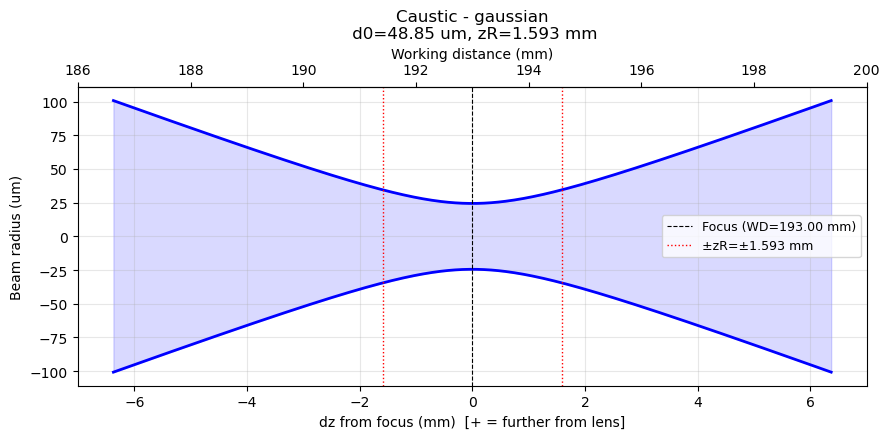

In [87]:
z_span_zR = 4.0
d0 = _focused_diameter_mm(); zR = _rayleigh_range_mm(d0); WD = working_distance_mm
z = np.linspace(-z_span_zR*zR, z_span_zR*zR, 400)
r_um = np.array([_diameter_at_dz(zi,d0,zR) for zi in z])*1e3/2
fig, ax = plt.subplots(figsize=(9,4.5))
ax.plot(z, r_um,'b-',lw=2); ax.plot(z,-r_um,'b-',lw=2)
ax.fill_between(z,-r_um,r_um,color='b',alpha=0.15)
ax.axvline(0,color='k',ls='--',lw=0.8,label=f'Focus (WD={WD:.2f} mm)')
ax.axvline(zR,color='r',ls=':',lw=1,label=f'±zR=±{zR:.3f} mm'); ax.axvline(-zR,color='r',ls=':',lw=1)
ax.set_xlabel('dz from focus (mm)  [+ = further from lens]')
ax.set_ylabel('Beam radius (um)')
ax.set_title(f'Caustic - {beam_profile}\n d0={d0*1e3:.2f} um, zR={zR:.3f} mm')
ax.legend(fontsize=9); ax.grid(True,alpha=0.3)
ax2 = ax.secondary_xaxis('top', functions=(lambda x:x+WD, lambda x:x-WD))
ax2.set_xlabel('Working distance (mm)')
plt.tight_layout(); plt.show()

## Section 7 - Calculated Keyhole Number Ke, Energy Density E*, Estimated ΔT

In [88]:
# ============================================================
# KEYHOLE NUMBER (Ke)
# DIMENSIONLESS ENERGY DENSITY (E*)
# ESTIMATED TEMPERATURE RISE (ΔT)
# ============================================================

print("Keyhole Number (Ke), Dimensionless Energy Density (E*), and Estimated Temperature Rise")

# ------------------------------------------------------------
# USER INPUTS
# ------------------------------------------------------------

# Beam diameter already calculated 
beam_diameter_um = target_diameter_um

# Laser parameters already defined elsewhere
laser_power_W = power_W
scan_speed_mm_s = scan_speed_mm_s

# ------------------------------------------------------------
# TEMPERATURE ESTIMATE INPUTS
# ------------------------------------------------------------
#
# This mass is USER DEFINED and represents the
# amount of material assumed to absorb the laser energy.
#
# It is NOT the actual melt-pool mass.
#
# Therefore ΔT should only be considered a
# first-order estimate.
#
mass_kg = 1e-6
dt_s = 0.001

# ------------------------------------------------------------
# 316L STAINLESS STEEL PROPERTIES
# ------------------------------------------------------------

eta = 0.33858

T_liquidus = 1673      # K
T_initial = 293        # K

rho = 8000            # kg/m³
Cp = 500              # J/(kg K)
k = 15                # W/(m K)

alpha = k/(rho*Cp)

# ------------------------------------------------------------
# UNIT CONVERSIONS
# ------------------------------------------------------------

P = laser_power_W

Vs = scan_speed_mm_s / 1000.0     # mm/s -> m/s

beam_radius_m = (beam_diameter_um/2.0) * 1e-6
beam_diameter_m = beam_diameter_um * 1e-6

# ------------------------------------------------------------
# KEYHOLE NUMBER
# ------------------------------------------------------------

Ke = (
    eta * P
) / (
    (T_liquidus - T_initial)
    * np.pi
    * rho
    * Cp
    * np.sqrt((alpha * Vs) * beam_radius_m**3)
)

# ------------------------------------------------------------
# DIMENSIONLESS ENERGY DENSITY
#
# Based on:
#
# E* = ηP /
#      [ρ Cp (Tm-T0) Vs d²]
#
# ------------------------------------------------------------

E_star = (
    eta * P
) / (
    rho
    * Cp
    * (T_liquidus - T_initial)
    * Vs
    * beam_diameter_m**2
)

# ------------------------------------------------------------
# ESTIMATED TEMPERATURE RISE
#
# Energy balance approximation only.
#
# Does NOT account for:
#   - conduction losses
#   - radiation losses
#   - convection
#   - latent heat of melting
#   - vaporization
#
# ------------------------------------------------------------

Delta_T = (
    eta * P * dt_s
) / (
    mass_kg * Cp
)

T_estimated = T_initial + Delta_T

# ------------------------------------------------------------
# OUTPUT
# ------------------------------------------------------------

print("\n======================================")
print("PROCESS METRICS")
print("======================================")

print(f"Beam Diameter            : {beam_diameter_um:.2f} um")
print(f"Beam Radius              : {beam_radius_m:.3e} m")

print(f"Laser Power              : {P:.1f} W")
print(f"Scan Speed               : {scan_speed_mm_s:.1f} mm/s")

print(f"Thermal Diffusivity      : {alpha:.3e} m²/s")

print("\n--------------------------------------")
print(f"Keyhole Number (Ke)      : {Ke:.3f}")

if Ke < 1:
    print("Predicted Regime         : Conduction Mode")
elif Ke < 10:
    print("Predicted Regime         : Transitional")
else:
    print("Predicted Regime         : Strong Keyhole")

print("\n--------------------------------------")
print(f"Dimensionless Energy E*  : {E_star:.3f}")

if E_star < 1:
    print("Energy Density Regime    : Low")
elif E_star < 10:
    print("Energy Density Regime    : Moderate")
else:
    print("Energy Density Regime    : High")

print("\n--------------------------------------")
print(f"Estimated Temp Rise ΔT   : {Delta_T:.1f} K")
print(f"Estimated Final Temp     : {T_estimated:.1f} K")

if T_estimated > T_liquidus:
    print("Prediction               : Above liquidus temperature")
else:
    print("Prediction               : Below liquidus temperature")

print("\nNOTE:")
print("ΔT is an approximate energy-balance estimate")
print("based on the USER-SPECIFIED heated mass.")
print("It should not be interpreted as the actual")
print("melt-pool temperature.")

Keyhole Number (Ke), Dimensionless Energy Density (E*), and Estimated Temperature Rise

PROCESS METRICS
Beam Diameter            : 200.00 um
Beam Radius              : 1.000e-04 m
Laser Power              : 200.0 W
Scan Speed               : 100.0 mm/s
Thermal Diffusivity      : 3.750e-06 m²/s

--------------------------------------
Keyhole Number (Ke)      : 6.377
Predicted Regime         : Transitional

--------------------------------------
Dimensionless Energy E*  : 3.067
Energy Density Regime    : Moderate

--------------------------------------
Estimated Temp Rise ΔT   : 135.4 K
Estimated Final Temp     : 428.4 K
Prediction               : Below liquidus temperature

NOTE:
ΔT is an approximate energy-balance estimate
based on the USER-SPECIFIED heated mass.
It should not be interpreted as the actual
melt-pool temperature.


## Section 8 - Reference Table (2-200 % growth)

In [89]:
growth = [2,10,15,30,50,100,200]
d0 = _focused_diameter_mm(); zR = _rayleigh_range_mm(d0); WD = working_distance_mm
print(f'd0 = {d0*1e3:.2f} um ({d0:.4f} mm),  zR = {zR:.4f} mm,  focal WD = {WD:.3f} mm\n')
h = f"{'Growth':>7} | {'|dz| mm':>9} | {'d (um)':>8} | {'d (mm)':>8} | {'WD-dz':>10} | {'WD+dz':>10}"
print(h); print('-'*len(h))
for g in growth:
    e = g/100.0; dz = zR*np.sqrt((1+e)**2-1); dn = d0*(1+e)
    print(f'{g:>6}% | {dz:>9.4f} | {dn*1e3:>8.2f} | {dn:>8.4f} | {WD-dz:>10.4f} | {WD+dz:>10.4f}')

d0 = 48.85 um (0.0489 mm),  zR = 1.5927 mm,  focal WD = 193.000 mm

 Growth |   |dz| mm |   d (um) |   d (mm) |      WD-dz |      WD+dz
-------------------------------------------------------------------
     2% |    0.3201 |    49.83 |   0.0498 |   192.6799 |   193.3201
    10% |    0.7298 |    53.74 |   0.0537 |   192.2702 |   193.7298
    15% |    0.9045 |    56.18 |   0.0562 |   192.0955 |   193.9045
    30% |    1.3230 |    63.51 |   0.0635 |   191.6770 |   194.3230
    50% |    1.7806 |    73.28 |   0.0733 |   191.2194 |   194.7806
   100% |    2.7586 |    97.71 |   0.0977 |   190.2414 |   195.7586
   200% |    4.5047 |   146.56 |   0.1466 |   188.4953 |   197.5047


## Notes
- **Flat-top / ring focal spot:** in real processing the spot is set by imaging, not diffraction. Enter it directly via `known_focus_diameter_um`. The old Airy formula (2.44 λf/D) only gives the diffraction *limit* and can be far smaller or larger than the delivered spot.
- **You cannot defocus below the waist.** Set `known_focus_diameter_um` to your smallest spot; all larger targets are reached by defocusing.
- **f vs WD:** f is used in equations; WD only reports stage position. For compound lenses f != WD (Smith 2007).
- **M2 for real beams:** measure via an ISO 11146 caustic scan and enter the fitted value (Siegman 1986).